In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import json
import xgboost as xgb

from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

In [2]:
df = pd.read_csv('data/listings.csv.gz')
len(df)

4961

In [3]:
df.columns

Index(['id', 'listing_url', 'scrape_id', 'last_scraped', 'source', 'name',
       'description', 'neighborhood_overview', 'picture_url', 'host_id',
       'host_url', 'host_profile_id', 'host_profile_url', 'host_name',
       'host_since', 'hosts_time_as_user_years', 'hosts_time_as_user_months',
       'hosts_time_as_host_years', 'hosts_time_as_host_months',
       'host_location', 'host_about', 'host_response_time',
       'host_response_rate', 'host_acceptance_rate', 'host_is_superhost',
       'host_thumbnail_url', 'host_picture_url', 'host_neighbourhood',
       'host_listings_count', 'host_total_listings_count',
       'host_verifications', 'host_has_profile_pic', 'host_identity_verified',
       'neighbourhood', 'neighbourhood_cleansed',
       'neighbourhood_group_cleansed', 'latitude', 'longitude',
       'property_type', 'room_type', 'accommodates', 'bathrooms',
       'bathrooms_text', 'bedrooms', 'beds', 'amenities', 'price',
       'price_quote_checkin_date', 'price_quote_c

In [4]:
df.head().T

,0,1,2,3,4
id,1434108413206019816,1613802572207908117,1674132228660847237,43057420,43057598
listing_url,https://www.airbnb.com/rooms/1434108413206019816,https://www.airbnb.com/rooms/1613802572207908117,https://www.airbnb.com/rooms/1674132228660847237,https://www.airbnb.com/rooms/43057420,https://www.airbnb.com/rooms/43057598
scrape_id,20260922161643,20260922161643,20260922161643,20260922161643,20260922161643
last_scraped,2026-09-24,2026-09-24,2026-09-24,2026-09-24,2026-09-24
source,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...
calculated_host_listings_count,1,212,1,13,13
calculated_host_listings_count_entire_homes,1,211,1,13,13
calculated_host_listings_count_private_rooms,0,1,0,0,0
calculated_host_listings_count_shared_rooms,0,0,0,0,0


**Cleaning data**

In [5]:
to_drop_replaced = []
to_drop_low_info = []
to_drop_id = []
to_drop_leakage = []
checked_cols = []

Check the missing values

In [6]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

neighborhood_overview           4961
host_since                      4961
host_acceptance_rate            4961
host_response_rate              4961
host_response_time              4961
host_total_listings_count       4961
host_neighbourhood              4961
host_verifications              4961
host_thumbnail_url              4961
calendar_updated                4961
bathrooms                       4961
neighbourhood_group_cleansed    4961
neighbourhood                   4961
instant_bookable                4961
source                          4526
host_about                      2750
host_location                   1855
first_review                     571
reviews_per_month                571
review_scores_checkin            571
review_scores_accuracy           571
review_scores_rating             571
review_scores_cleanliness        571
review_scores_communication      571
review_scores_location           571
review_scores_value              571
last_review                      571
e

Delete data with empty or almost empty columns  

In [7]:
columns_empty = missing[missing > len(df)*0.9].index
df = df.drop(columns=columns_empty)
len(df)

4961

In [8]:
columns_empty

Index(['source', 'neighborhood_overview', 'host_since', 'host_response_time',
       'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url',
       'host_neighbourhood', 'host_total_listings_count', 'host_verifications',
       'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms',
       'calendar_updated', 'instant_bookable'],
      dtype='str')

Delete data with missing price

In [9]:
df = df.drop(df[df.price.isnull()].index)
len(df)

4627

In [10]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

host_about                     2544
host_location                  1717
review_scores_communication     501
review_scores_location          501
first_review                    501
review_scores_rating            501
last_review                     501
reviews_per_month               501
review_scores_value             501
review_scores_cleanliness       501
review_scores_accuracy          501
review_scores_checkin           501
license                          93
beds                             47
has_availability                  6
minimum_minimum_nights            3
maximum_minimum_nights            3
minimum_nights                    3
maximum_nights                    3
minimum_maximum_nights            3
maximum_maximum_nights            3
bathrooms_text                    1
description                       1
dtype: int64

Delete some unfinished offers. First to check if these are same raws

In [11]:
cols = missing[missing == 3].index
df[cols].isnull().any(axis=1).sum()

np.int64(3)

In [12]:
df = df.dropna(subset=cols)
len(df)

4624

Dropping the row with missing bathroom description

In [13]:
df = df.drop(df[df.bathrooms_text.isnull()].index)
len(df)

4623

Analyse what's left

In [14]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

host_about                     2541
host_location                  1716
last_review                     501
first_review                    501
review_scores_rating            501
review_scores_checkin           501
review_scores_cleanliness       501
review_scores_accuracy          501
review_scores_location          501
review_scores_value             501
reviews_per_month               501
review_scores_communication     501
license                          92
beds                             47
has_availability                  6
description                       1
dtype: int64

In [15]:
df['host_location'].value_counts()

host_location
Thessaloniki, Greece      2410
Greece                      96
Athens, Greece              56
Heraklion, Greece           39
London, United Kingdom      24
                          ... 
Israel                       1
Paris, France                1
Strasbourg, France           1
Cologne, Germany             1
Nicosia, Cyprus              1
Name: count, Length: 121, dtype: int64

Cleaning price

In [16]:
df['price'].head()

0    $96.60
1    $40.00
2    $60.00
3    $94.00
4    $94.00
Name: price, dtype: str

In [17]:
df['price'] = df['price'].str.replace('$', '')
df['price'] = df['price'].str.replace(',', '')

df.price = pd.to_numeric(df.price)
df.price.head()

0    96.6
1    40.0
2    60.0
3    94.0
4    94.0
Name: price, dtype: float64

**Feature engineering**

1. Host location (categories)

In [18]:
def host_location_category(loc): 
    if pd.isna(loc): 
        return 'unknown' 
    if 'Thessaloniki' in loc: 
        return 'thessaloniki' 
    if'Greece' in loc: 
        return 'greece'
    return 'abroad' 
    
df['host_location_cat'] = df['host_location'].apply(host_location_category) 

In [19]:
df['host_location_cat'].value_counts()

host_location_cat
thessaloniki    2410
unknown         1716
greece           372
abroad           125
Name: count, dtype: int64

In [20]:
to_drop_replaced.append('host_location')

2. Reviews
   a) make a new column 'has_reviews'
   b) 'reviews_per_month' fill with 0

In [21]:
def has_reviews_category(loc): 
    if loc == 0: 
        return 0 
    return 1 
    
df['has_reviews'] = df['number_of_reviews'].apply(has_reviews_category) 

In [22]:
df['has_reviews'].value_counts()

has_reviews
1    4122
0     501
Name: count, dtype: int64

In [23]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

After splitting, fill all reviews columns with the median

In [24]:
checked_cols.append('has_reviews')
checked_cols.append('reviews_per_month')

In [25]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

host_about                     2541
host_location                  1716
last_review                     501
first_review                    501
review_scores_cleanliness       501
review_scores_accuracy          501
review_scores_rating            501
review_scores_communication     501
review_scores_location          501
review_scores_value             501
review_scores_checkin           501
license                          92
beds                             47
has_availability                  6
description                       1
dtype: int64

3. License

In [26]:
df['license'].value_counts()

license
Exempt              36
0933Κ13000111100    15
0933Κ13000118900    15
0933Κ13000125400    11
1037314             10
                    ..
00003955113          1
36234670000          1
0933Κ13000130600     1
00003652492          1
00003941335          1
Name: count, Length: 4244, dtype: int64

In [27]:
def license_ok(loc): 
    if pd.isna(loc): 
        return 0
    return 1 
    
df['license_ok'] = df['license'].apply(license_ok) 

In [28]:
df['license_ok'].value_counts()

license_ok
1    4531
0      92
Name: count, dtype: int64

4. Host description (make a flag if host wrote the description)

In [29]:
df[df['host_about'].str.len() < 20]['host_about']

146      Business traveller
270          Hello everyone
295                      :)
325            Hello guest!
414                       .
523       Welcome to Nikiti
675            Hello guest!
743                   calm!
806          Hi i am Hlias.
932                Georgios
942                 Dimitra
1052              Traveller
1090       Hi I m Katerina!
1106            Airbnb user
1160           Hello guest!
1357             Καλησπέρα!
1505    Photographer Artist
1536        Enjoy your life
1597     Hi, i am Dimitris.
1641     Loves traveling ❤️
1881               Christos
1933           Hi I'm Effie
2019         Hi i am Hlias.
2152               Victoria
2226    sotiris from Greece
2559    Greece Thessaloniki
2561    Greece Thessaloniki
2670               Γεια σας
2749               Γεια σας
2798      Skopje, Macedonia
2907               Γεια σας
3285               Γεια σας
3327           Business man
3332           Business man
3391                  enjoy
3742           Thess

In [30]:
df['host_has_descr'] = (df['host_about'].str.len().fillna(0) >= 20).astype(int)
checked_cols.append('host_has_descr')
to_drop_replaced.append('host_about')

In [31]:
checked_cols.append('license_ok')
to_drop_replaced.append('license')

5. Amenities. (Create a new feature number of amenities)

In [32]:
df['n_amenities'] = df['amenities'].apply(json.loads).str.len()
to_drop_replaced.append('amenities')
df['n_amenities'].describe()

count    4623.000000
mean       33.598096
std        13.068780
min         2.000000
25%        26.000000
50%        35.000000
75%        42.000000
max        87.000000
Name: n_amenities, dtype: float64

6. Checking 'has availability'

In [33]:
df['has_availability'].value_counts()

has_availability
t    4617
Name: count, dtype: int64

Delete non unique columns

In [34]:
df.nunique().sort_values(ascending=True)

scrape_id                    1
has_availability             1
host_has_profile_pic         2
last_scraped                 2
host_identity_verified       2
                          ... 
license                   4244
name                      4552
picture_url               4574
id                        4623
listing_url               4623
Length: 80, dtype: int64

In [35]:
nunique = df.nunique()
columns_nonunique = nunique[nunique == 1].index
df = df.drop(columns=columns_nonunique)

7. First and last reviews. Cleaning dates (new columns - to count how many days from the first review and from the last, the days will be counted from the last scraped date)

In [36]:
df['days_since_last_review'] = (pd.to_datetime(df.last_scraped) - pd.to_datetime(df.last_review)).dt.days
df['days_since_last_review'].isnull().sum()

np.int64(501)

In [37]:
df['days_since_first_review'] = (pd.to_datetime(df.last_scraped) - pd.to_datetime(df.first_review)).dt.days
df['days_since_first_review'].isnull().sum()

np.int64(501)

In [38]:
to_drop_replaced.append('last_scraped')
to_drop_replaced.append('last_review')
to_drop_replaced.append('first_review')
checked_cols.append('days_since_first_review')
checked_cols.append('days_since_last_review')

8. Working with bathrooms categories. 87% of listings have exactly 1 bath, so creating only  2 new flags - Bathroom numbers (1 if more than 1, 0 if 1 or less) and Shared bathroom (=1 if shared)

In [39]:
df['bathrooms_text'].value_counts()

bathrooms_text
1 bath               4044
1.5 baths             227
2 baths               183
1 private bath        109
1 shared bath          14
0 baths                11
3 baths                10
2.5 baths              10
Half-bath               7
2 shared baths          2
0 shared baths          2
1.5 shared baths        1
4 baths                 1
5 baths                 1
Private half-bath       1
Name: count, dtype: int64

In [40]:
df['bathrooms_num'] = df['bathrooms_text'].str.extract(r'(\d+\.?\d*)')[0].astype(float)
df['bathrooms_num'] = df['bathrooms_num'].fillna(0.5)
df['bathrooms_num'] = (df['bathrooms_num'] > 1).astype(int)
df['bathrooms_num'].sum()

np.int64(435)

In [41]:
df['bathrooms_shared'] = df['bathrooms_text'].str.contains('shared', case=False).astype(int)
df['bathrooms_shared'].sum()
to_drop_replaced.append('bathrooms_text')

In [42]:
checked_cols.append('bathrooms_shared')
checked_cols.append('bathrooms_num')

**EDA**

Analyse price

In [43]:
df['price'].describe()

count     4623.000000
mean       100.878890
std        259.006708
min         18.290000
25%         63.000000
50%         80.000000
75%        108.000000
max      12021.500000
Name: price, dtype: float64

<Axes: xlabel='price', ylabel='Count'>

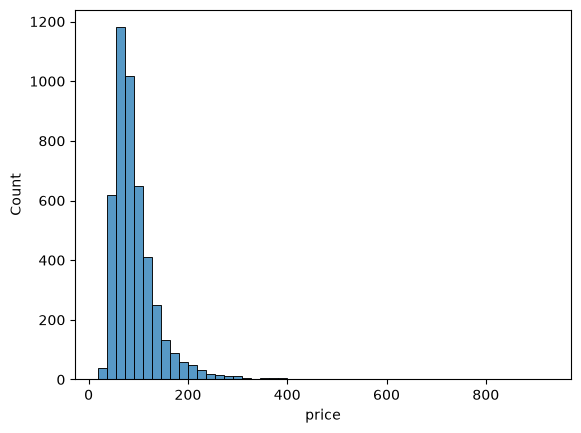

In [44]:
sns.histplot(df.price[df.price < 1000], bins=50)

In [45]:
df.price[df.price > 1000]

135      1651.00
790     12021.50
1477     5776.50
2979     2316.27
4242    10700.50
4294     1157.00
Name: price, dtype: float64

Delete prices > 1000. 2 prices about 10000 euros are clearly placeholders; values above 1000 euros look unrealistic for Thessaloniki

In [46]:
df = df.drop(df[df.price > 1000].index)
len(df)

4617

In [47]:
df['price'].skew()

np.float64(4.696697731902987)

Check if it looks like real listings (from 500 and up)

In [48]:
pd.set_option('display.max_colwidth', 200)
df[df.price > 500].description

233                       Next to the Rotunda, Rock n' Roll 1 is a unique apartment. With unique aesthetics and decoration, fully equipped, in the city center, next to all the great monuments of Thessaloniki
234         Rock n Roll 2 is a unique apartment next to the Rotunda.  In a very central location, a fully equipped house with unique aesthetics and decoration. Next to all the great monuments of Thessaloniki
1036                                                                                                                                          The apartment has modern decoration, has a fully equipped kitchen
1078    The apartment has 1 large bedroom with a double bed, a living room with two sofas where one becomes a comfortable bed, a fully equipped kitchen, a bathroom,  and a small room with a single bed. Th...
1112    This flat 130 sq.m. is located in the most desirable place of Thessaloniki between Aristotelous square and White Tower. <br />It consists of a large living area

Apply log

In [49]:
df['log_price'] = np.log1p(df['price'])
df['log_price'].skew()

np.float64(0.7727375662648258)

<Axes: xlabel='log_price', ylabel='Count'>

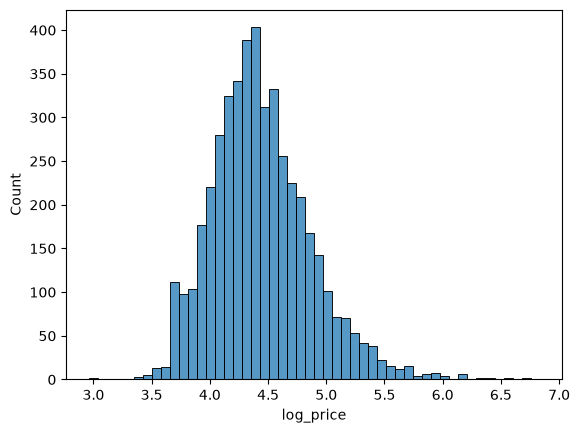

In [50]:
sns.histplot(df.log_price, bins=50)

Skew of Price: 4.69
Skew of Log Price: 0.77
After the log transformation, skewness dropped from 4.69 to 0.77 (moderate), so the model will be trained on log_price

Checking numerical columns (+ separate all 'id' columns)

In [51]:
numerical_cols = df.select_dtypes(include='number').columns
numerical_cols

Index(['id', 'host_id', 'host_profile_id', 'hosts_time_as_user_years',
       'hosts_time_as_user_months', 'hosts_time_as_host_years',
       'hosts_time_as_host_months', 'host_listings_count', 'latitude',
       'longitude', 'accommodates', 'bedrooms', 'beds', 'price',
       'price_quote_total_price', 'price_quote_price_per_night',
       'minimum_nights', 'maximum_nights', 'minimum_minimum_nights',
       'maximum_minimum_nights', 'minimum_maximum_nights',
       'maximum_maximum_nights', 'minimum_nights_avg_ntm',
       'maximum_nights_avg_ntm', 'availability_30', 'availability_60',
       'availability_90', 'availability_365', 'number_of_reviews',
       'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy',
       'number_of_reviews_ly', 'estimated_occupancy_l365d',
       'estimated_revenue_l365d', 'review_scores_rating',
       'review_scores_accuracy', 'review_scores_cleanliness',
       'review_scores_checkin', 'review_scores_communication',
       'review_sco

Remove from numerical columns all checked, all with id and all with prices

In [52]:
id_cols = [c for c in numerical_cols if c == 'id' or c.endswith('_id')]
numerical_cols = [c for c in numerical_cols if c not in id_cols  and c not in checked_cols and 'price' not in c]

In [53]:
len(numerical_cols)

41

In [54]:
def checking_num_col(s): 
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    outliners = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    max_share = (s.dropna() == s.max()).mean()
    skew = s.skew()
    null_quant = s.isnull().sum()
    negative_quant = (s < 0).sum()
    result = {'outliers': outliners, 'max_share': max_share, 'skew': skew, 'negative': negative_quant, 'isnull': null_quant}
    return result 

In [55]:
results = {col: checking_num_col(df[col]) for col in numerical_cols}
summary = pd.DataFrame(results).T

Checking skew

In [56]:
summary.sort_values('skew', ascending=False)

,outliers,max_share,skew,negative,isnull
minimum_nights,166.0,0.000217,31.121473,0.0,0.0
minimum_minimum_nights,166.0,0.000217,31.121473,0.0,0.0
minimum_nights_avg_ntm,311.0,0.000217,26.736613,0.0,0.0
maximum_minimum_nights,134.0,0.000217,24.991777,0.0,0.0
calculated_host_listings_count_shared_rooms,8.0,0.001733,23.968730,0.0,0.0
calculated_host_listings_count_private_rooms,496.0,0.004332,7.621078,0.0,0.0
host_listings_count,780.0,0.000217,5.179999,0.0,0.0
number_of_reviews,416.0,0.000217,4.247249,0.0,0.0
calculated_host_listings_count,711.0,0.043102,2.751235,0.0,0.0
calculated_host_listings_count_entire_homes,711.0,0.043102,2.747198,0.0,0.0


In [57]:
(df['minimum_nights']>30).sum()

np.int64(17)

Delete 17 listings because they are long-term rentals

In [58]:
df = df[df['minimum_nights'] <= 30]

In [59]:
results = {col: checking_num_col(df[col]) for col in numerical_cols}
summary = pd.DataFrame(results).T

In [60]:
summary.sort_values('skew', ascending=True)

,outliers,max_share,skew,negative,isnull
review_scores_checkin,336.0,0.310857,-6.403948,0.0,492.0
review_scores_communication,371.0,0.345424,-6.331529,0.0,492.0
review_scores_accuracy,294.0,0.259981,-5.006632,0.0,492.0
review_scores_cleanliness,297.0,0.270448,-4.167566,0.0,492.0
review_scores_value,293.0,0.176972,-4.035284,0.0,492.0
review_scores_rating,289.0,0.245375,-4.010280,0.0,492.0
review_scores_location,208.0,0.223953,-3.781313,0.0,492.0
availability_eoy,415.0,0.048913,-1.238572,0.0,0.0
availability_90,414.0,0.068478,-1.231103,0.0,0.0
latitude,732.0,0.000217,-1.205046,0.0,0.0


In [61]:
df['calculated_host_listings_count_shared_rooms'].value_counts()

calculated_host_listings_count_shared_rooms
0    4592
1       8
Name: count, dtype: int64

The column calculated_host_listings_count_shared_rooms to drop because only 8 non-zero values

In [62]:
to_drop_low_info.append('calculated_host_listings_count_shared_rooms')

All other skew values < 10, we will decide later to apply log for Linear Regression

Checking negative and null values

In [63]:
summary.sort_values('negative', ascending=True)

,outliers,max_share,skew,negative,isnull
hosts_time_as_user_years,0.0,0.000217,0.015918,0.0,0.0
hosts_time_as_user_months,0.0,0.095435,0.039599,0.0,0.0
hosts_time_as_host_years,13.0,0.002826,0.318598,0.0,0.0
hosts_time_as_host_months,0.0,0.084565,0.237553,0.0,0.0
host_listings_count,780.0,0.000217,5.171393,0.0,0.0
latitude,732.0,0.000217,-1.205046,0.0,0.0
longitude,165.0,0.000217,1.690377,0.0,0.0
accommodates,196.0,0.001304,1.740135,0.0,0.0
bedrooms,47.0,0.000217,1.195473,0.0,0.0
beds,368.0,0.000439,2.486911,0.0,47.0


In [64]:
summary.sort_values('isnull', ascending=False)

,outliers,max_share,skew,negative,isnull
review_scores_rating,289.0,0.245375,-4.010280,0.0,492.0
review_scores_location,208.0,0.223953,-3.781313,0.0,492.0
review_scores_checkin,336.0,0.310857,-6.403948,0.0,492.0
review_scores_accuracy,294.0,0.259981,-5.006632,0.0,492.0
review_scores_cleanliness,297.0,0.270448,-4.167566,0.0,492.0
review_scores_communication,371.0,0.345424,-6.331529,0.0,492.0
review_scores_value,293.0,0.176972,-4.035284,0.0,492.0
beds,368.0,0.000439,2.486911,0.0,47.0
hosts_time_as_user_years,0.0,0.000217,0.015918,0.0,0.0
bedrooms,47.0,0.000217,1.195473,0.0,0.0


we already know about 492 nulls in reviews, will be filled with median after splitting, as well as 'beds'

Checking max share (manual check for all columns > 5%)

In [65]:
summary.sort_values('max_share', ascending=False)

,outliers,max_share,skew,negative,isnull
maximum_nights,0.0,0.359565,0.299789,0.0,0.0
maximum_maximum_nights,0.0,0.359565,0.299789,0.0,0.0
minimum_maximum_nights,0.0,0.345870,0.348288,0.0,0.0
maximum_nights_avg_ntm,0.0,0.345870,0.317408,0.0,0.0
review_scores_communication,371.0,0.345424,-6.331529,0.0,492.0
review_scores_checkin,336.0,0.310857,-6.403948,0.0,492.0
review_scores_cleanliness,297.0,0.270448,-4.167566,0.0,492.0
review_scores_accuracy,294.0,0.259981,-5.006632,0.0,492.0
review_scores_rating,289.0,0.245375,-4.010280,0.0,492.0
review_scores_location,208.0,0.223953,-3.781313,0.0,492.0


Adding to the Drop list all columns with 'nights' except 'minimum_nights' because others have around the same skew and outliers

In [66]:
night_cols = [c for c in df.columns if 'nights' in c and c != 'minimum_nights']
to_drop_low_info.extend(night_cols)

In [67]:
df['review_scores_communication'].sort_values(ascending=False)

15      5.0
4957    5.0
4943    5.0
4938    5.0
4933    5.0
       ... 
4955    NaN
4956    NaN
4958    NaN
4959    NaN
4960    NaN
Name: review_scores_communication, Length: 4600, dtype: float64

In [68]:
df['review_scores_checkin'].sort_values(ascending=False)

14      5.0
4908    5.0
4912    5.0
4915    5.0
4916    5.0
       ... 
4955    NaN
4956    NaN
4958    NaN
4959    NaN
4960    NaN
Name: review_scores_checkin, Length: 4600, dtype: float64

All reviews columns are normal, all have values from 1 to 5. NaN we will fill later. 

In [69]:
df['hosts_time_as_user_years'].sort_values(ascending=False)

603     16
736     15
2840    15
643     15
644     15
        ..
4902     0
75       0
4845     0
4849     0
4854     0
Name: hosts_time_as_user_years, Length: 4600, dtype: int64

We will aggregate 4 columns in 2, counting in month time as user and host and drop 4 old columns

In [70]:
df['host_tenure_month'] = df['hosts_time_as_host_months'] + df['hosts_time_as_host_years'] * 12
df['user_tenure_month'] = df['hosts_time_as_user_months'] + df['hosts_time_as_user_years'] * 12
host_user_columns = [c for c in df.columns if 'hosts_time_as_' in c]
to_drop_replaced.extend(host_user_columns)

In [71]:
df['availability_90'].sort_values(ascending=False)

1462    90
1449    90
1450    90
1446    90
1513    90
        ..
96       0
4848     0
61       0
1461     0
4930     0
Name: availability_90, Length: 4600, dtype: int64

In [72]:
df['estimated_occupancy_l365d'].sort_values(ascending=False)

47      255
2317    255
2944    255
791     255
2442    255
       ... 
4909      0
4910      0
4913      0
4917      0
4919      0
Name: estimated_occupancy_l365d, Length: 4600, dtype: int64

'estimated_occupancy_l365d' derived from review counts with Inside Airbnb’s own assumptions; duplicates existing review features 

In [73]:
to_drop_low_info.append('estimated_occupancy_l365d')

Drop all columns we don't need

In [74]:
to_drop_id = id_cols
to_drop_leakage.append('estimated_revenue_l365d')
df =  df.drop(columns=(to_drop_id + to_drop_leakage + to_drop_replaced + to_drop_low_info))
df.columns

Index(['listing_url', 'name', 'description', 'picture_url', 'host_url',
       'host_profile_url', 'host_name', 'host_is_superhost',
       'host_picture_url', 'host_listings_count', 'host_has_profile_pic',
       'host_identity_verified', 'neighbourhood_cleansed', 'latitude',
       'longitude', 'property_type', 'room_type', 'accommodates', 'bedrooms',
       'beds', 'price', 'price_quote_checkin_date',
       'price_quote_checkout_date', 'price_quote_total_price',
       'price_quote_price_per_night', 'price_quote_raw', 'minimum_nights',
       'availability_30', 'availability_60', 'availability_90',
       'availability_365', 'calendar_last_scraped', 'number_of_reviews',
       'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy',
       'number_of_reviews_ly', 'review_scores_rating',
       'review_scores_accuracy', 'review_scores_cleanliness',
       'review_scores_checkin', 'review_scores_communication',
       'review_scores_location', 'review_scores_value',
   

Checking correlation with price

In [75]:
numerical_cols = df.select_dtypes(include='number').columns
numerical_cols = [c for c in numerical_cols if 'price' not in c]

In [76]:
df[numerical_cols].corrwith(df.log_price).abs().sort_values(ascending=False)

bedrooms                                        0.495684
accommodates                                    0.441038
beds                                            0.379204
bathrooms_num                                   0.322069
calculated_host_listings_count_entire_homes     0.257219
calculated_host_listings_count                  0.256889
n_amenities                                     0.220571
review_scores_location                          0.210655
review_scores_rating                            0.194495
number_of_reviews_ly                            0.188129
review_scores_cleanliness                       0.176412
number_of_reviews_ltm                           0.168808
review_scores_accuracy                          0.158264
number_of_reviews                               0.150610
review_scores_value                             0.150585
latitude                                        0.142192
reviews_per_month                               0.142084
review_scores_communication    

No single numeric feature strongly predicts price (max correlation 0.496 with bedrooms); price depends on a combination of features 

In [77]:
pairs = []
for col in numerical_cols:
    others = [c for c in numerical_cols if c != col]
    c = df[others].corrwith(df[col])
    strong = c[c.abs() > 0.8]
    for name, value in strong.items(): 
        pairs.append((col, name, value)) 
pd.DataFrame(pairs, columns=['feature', 'with', 'corr']) 


,feature,with,corr
0,availability_30,availability_60,0.905201
1,availability_30,availability_90,0.801574
2,availability_60,availability_30,0.905201
3,availability_60,availability_90,0.957955
4,availability_60,availability_eoy,0.943364
5,availability_90,availability_30,0.801574
6,availability_90,availability_60,0.957955
7,availability_90,availability_eoy,0.994359
8,number_of_reviews_ltm,number_of_reviews_ly,0.800812
9,number_of_reviews_ltm,reviews_per_month,0.843617


Removing features that are highly correlated with each other

In [78]:
availability_cols = [c for c in df.columns if 'availability_' in c and c != 'availability_90']
reviews_cols = [c for c in df.columns if ('review_scores_' in c or 'number_of_reviews_l' in c) 
                and c != 'review_scores_rating' and c != 'review_scores_location']
to_drop_correlated = ['calculated_host_listings_count_entire_homes']
to_drop_correlated.extend(availability_cols)
to_drop_correlated.extend(reviews_cols)

In [79]:
df =  df.drop(columns=to_drop_correlated)
df.columns

Index(['listing_url', 'name', 'description', 'picture_url', 'host_url',
       'host_profile_url', 'host_name', 'host_is_superhost',
       'host_picture_url', 'host_listings_count', 'host_has_profile_pic',
       'host_identity_verified', 'neighbourhood_cleansed', 'latitude',
       'longitude', 'property_type', 'room_type', 'accommodates', 'bedrooms',
       'beds', 'price', 'price_quote_checkin_date',
       'price_quote_checkout_date', 'price_quote_total_price',
       'price_quote_price_per_night', 'price_quote_raw', 'minimum_nights',
       'availability_90', 'calendar_last_scraped', 'number_of_reviews',
       'review_scores_rating', 'review_scores_location',
       'calculated_host_listings_count',
       'calculated_host_listings_count_private_rooms', 'reviews_per_month',
       'host_location_cat', 'has_reviews', 'license_ok', 'host_has_descr',
       'n_amenities', 'days_since_last_review', 'days_since_first_review',
       'bathrooms_num', 'bathrooms_shared', 'log_price', '

Drop all price_quote columns as well

In [80]:
to_drop_price_quote = [c for c in df.columns if c.startswith('price_quote')]
df =  df.drop(columns=to_drop_price_quote)

In [81]:
def select_categorical_cols(df):
    categorical_cols = df.select_dtypes(exclude='number').columns.tolist()
    return categorical_cols

In [82]:
categorical_cols = select_categorical_cols(df)

In [83]:
to_drop_categorical_cols = [c for c in df.columns if c.endswith('_url')]
to_drop_categorical_cols.append('name')
to_drop_categorical_cols.append('host_name')
to_drop_categorical_cols.append('description')
to_drop_categorical_cols.append('calendar_last_scraped')
df = df.drop(columns=to_drop_categorical_cols)
categorical_cols = select_categorical_cols(df)
categorical_cols

['host_is_superhost',
 'host_has_profile_pic',
 'host_identity_verified',
 'neighbourhood_cleansed',
 'property_type',
 'room_type',
 'host_location_cat']

In [84]:
global_price = df.price.median()
for c in categorical_cols:
    print(c)
    df_group = df.groupby(c, dropna=False).price.agg(['median', 'count'])
    df_group['diff'] = df_group['median'] - global_price
    df_group['risk'] = df_group['median'] / global_price
    display(df_group.sort_values('risk'))
    print()
    print()


host_is_superhost


,median,count,diff,risk
host_is_superhost,,,,
f,80.0,2802,0.0,1.0
t,80.0,1798,0.0,1.0




host_has_profile_pic


,median,count,diff,risk
host_has_profile_pic,,,,
t,80.0,4356,0.0,1.0000
f,83.0,244,3.0,1.0375




host_identity_verified


,median,count,diff,risk
host_identity_verified,,,,
f,78.25,36,-1.75,0.978125
t,80.00,4564,0.00,1.000000


... (4 outputs left out)



room_type


,median,count,diff,risk
room_type,,,,
Shared room,40.5,3,-39.5,0.50625
Private room,69.5,134,-10.5,0.86875
Entire home/apt,80.0,4463,0.0,1.00000




host_location_cat


,median,count,diff,risk
host_location_cat,,,,
thessaloniki,76.00,2400,-4.00,0.950000
greece,84.00,366,4.00,1.050000
unknown,84.71,1710,4.71,1.058875
abroad,88.85,124,8.85,1.110625


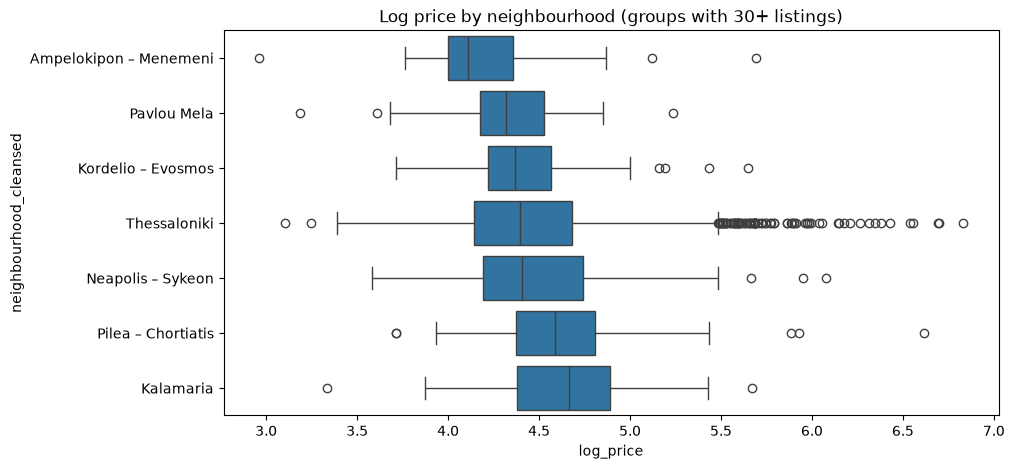

In [85]:
counts = df['neighbourhood_cleansed'].value_counts()
big_neighbourhoods = counts[counts >= 30].index
df_big = df[df['neighbourhood_cleansed'].isin(big_neighbourhoods)]
order = df_big.groupby('neighbourhood_cleansed')['log_price'].median().sort_values().index


plt.figure(figsize=(10, 5))
sns.boxplot(data=df_big, x='log_price', y='neighbourhood_cleansed', order=order)
plt.title('Log price by neighbourhood (groups with 30+ listings)')
plt.show()


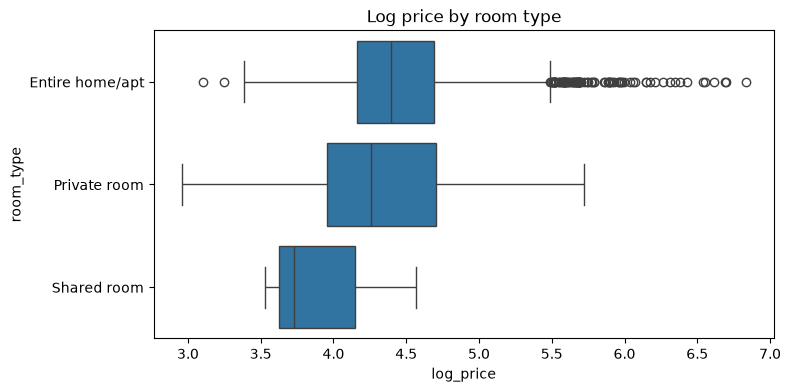

In [86]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x='log_price', y='room_type')
plt.title('Log price by room type')
plt.show()


Categorical features. Group analysis 

For each categorical feature I compared the median price of each group with the global median price (`risk` = group median / global median). Only groups with at least 30 listings are considered reliable. 
- `neighbourhood_cleansed` is the only feature with large groups outside the 0.8–1.2 range: Kalamaria (1.31, 163 listings) and Pilea – Chortiatis (1.21, 63 listings) are more expensive suburbs, 
Ampelokipi
– Menemeni (0.75, 59 listings) is cheaper. Location affects the price in both directions. 
- `room_type` is very unbalanced: 4463 listings are `Entire home/apt` and only 134 are `Private room`. A private room is about 13% cheaper than the global median (`risk` = 0.87). 
- `host_location_cat`: hosts living abroad charge about 11% more (`risk` = 1.11, 124 listings).
- `host_is_superhost`, `host_has_profile_pic` and `host_identity_verified` have almost no effect on price (`risk` ≈ 1).
- `property_type`: large groups have `risk` between 0.87 and 1.06, so they add little beyond `room_type`. All small groups (less than 30 listings) have `risk` above 1.2, for example `Entire villa` (3.33, 2 listings), but they are too small to be reliable. `property_type` will be dropped; `room_type` keeps the main difference (entire home vs. private room).

In [87]:
to_drop_categorical_analysis = ['property_type'] 
df = df.drop(columns=to_drop_categorical_analysis) 

**Data split and missing values**

In [88]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

len(df_train), len(df_val), len(df_test)

(2760, 920, 920)

In [89]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.log_price.values
y_val = df_val.log_price.values
y_test = df_test.log_price.values

to_drop = ['price', 'log_price']
df_train = df_train.drop(columns=to_drop)
df_val = df_val.drop(columns=to_drop)
df_test = df_test.drop(columns=to_drop)
df_train.columns

Index(['host_is_superhost', 'host_listings_count', 'host_has_profile_pic',
       'host_identity_verified', 'neighbourhood_cleansed', 'latitude',
       'longitude', 'room_type', 'accommodates', 'bedrooms', 'beds',
       'minimum_nights', 'availability_90', 'number_of_reviews',
       'review_scores_rating', 'review_scores_location',
       'calculated_host_listings_count',
       'calculated_host_listings_count_private_rooms', 'reviews_per_month',
       'host_location_cat', 'has_reviews', 'license_ok', 'host_has_descr',
       'n_amenities', 'days_since_last_review', 'days_since_first_review',
       'bathrooms_num', 'bathrooms_shared', 'host_tenure_month',
       'user_tenure_month'],
      dtype='str')

In [90]:
to_fill_median = df_train.columns[df_train.isnull().any()].tolist()
to_fill_median

['beds',
 'review_scores_rating',
 'review_scores_location',
 'days_since_last_review',
 'days_since_first_review']

In [91]:
median_data = df_train[to_fill_median].median()
df_train = df_train.fillna(median_data)
df_val = df_val.fillna(median_data)
df_test = df_test.fillna(median_data)

***MODELS***

**Linear Regression**

In [92]:
train_dicts = df_train.to_dict(orient='records')

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)
model = Ridge(alpha=1.0)
model.fit(X_train, y_train)


,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [93]:
y_pred = model.predict(X_train)
rmse = root_mean_squared_error(y_train, y_pred)
print('rmse train:', rmse)

rmse train: 0.3274434545651775


In [94]:
val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)
y_pred_val = model.predict(X_val)
rmse  = root_mean_squared_error(y_val, y_pred_val)
print('rmse validation:', rmse)

rmse validation: 0.3265707399465264


In [95]:
n_alpha_array = [1, 5, 10, 15, 20, 30, 40, 50]
for n in n_alpha_array:
    model = Ridge(alpha=n)
    model.fit(X_train, y_train)
    y_pred_val = model.predict(X_val)
    rmse  = root_mean_squared_error(y_val, y_pred_val)
    print('rmse validation:', n, rmse)

rmse validation: 1 0.3265707399465264
rmse validation: 5 0.32647613455443164
rmse validation: 10 0.3265083144134855
rmse validation: 15 0.3264542776270429
rmse validation: 20 0.32658378856976394
rmse validation: 30 0.32701658602002
rmse validation: 40 0.3272053392962459
rmse validation: 50 0.32740824852779793


*Result:* Ridge, linear regression, alpha 5-15 give the same RMSE(0.3265), alpha=5 chosen

Now we will try to apply log to features with high skew

In [96]:
df_train_new = df_train.copy()
df_val_new = df_val.copy()
df_test_new = df_test.copy()

In [97]:
num = df_train.select_dtypes(include='number') 
num = num.loc[:, num.nunique() > 2] 
skewed_cols = num.columns[num.skew() > 2].tolist() 
skewed_cols 


['host_listings_count',
 'beds',
 'minimum_nights',
 'number_of_reviews',
 'calculated_host_listings_count',
 'calculated_host_listings_count_private_rooms',
 'reviews_per_month',
 'days_since_last_review']

In [98]:
df_train_new[skewed_cols] = np.log1p(df_train_new[skewed_cols])
df_val_new[skewed_cols]= np.log1p(df_val[skewed_cols])
df_test_new[skewed_cols] = np.log1p(df_test[skewed_cols])

In [99]:
train_dicts = df_train_new.to_dict(orient='records')

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)
model = Ridge(alpha=1.0)
model.fit(X_train, y_train)
y_pred = model.predict(X_train)
rmse = root_mean_squared_error(y_train, y_pred)
print('rmse train:', rmse)

rmse train: 0.32884083673071796


In [100]:
val_dicts = df_val_new.to_dict(orient='records')
X_val = dv.transform(val_dicts)
n_alpha_array = [1, 5, 10, 15, 20, 30, 40, 50]
for n in n_alpha_array:
    model = Ridge(alpha=n)
    model.fit(X_train, y_train)
    y_pred_val = model.predict(X_val)
    rmse  = root_mean_squared_error(y_val, y_pred_val)
    print('rmse validation:', n, rmse)

rmse validation: 1 0.33587449668893576
rmse validation: 5 0.3357198106482574
rmse validation: 10 0.3356381433249652
rmse validation: 15 0.3350678418578752
rmse validation: 20 0.33519613701061446
rmse validation: 30 0.33588181034508363
rmse validation: 40 0.3361445376226989
rmse validation: 50 0.33641939074350063


*Result:* Log transformation of skewed features (skew > 2) made the validation RMSE worse (0.3351 vs 0.3265), so the linear model is trained on the original features.

**Random forest**

In [101]:
train_dicts = df_train.to_dict(orient='records')

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)

val_dicts = df_val.to_dict(orient='records')
X_val = dv.transform(val_dicts)

n_est_array = [100, 150, 200, 250, 300]
max_depth_array = [10, 15, 20, 25, 30, 35, 40]
n_min_sample_leaf_array = [1, 2, 3, 5, 10]

result = []

for m_depth in max_depth_array:
    for n_est in n_est_array:
        for m_leaf in n_min_sample_leaf_array:
            dt = RandomForestRegressor(n_estimators=n_est, max_depth=m_depth, min_samples_leaf=m_leaf, random_state=1, n_jobs=-1)
            dt.fit(X_train, y_train)
            y_pred = dt.predict(X_val)
            rmse  = root_mean_squared_error(y_val, y_pred)
            result.append((m_depth, n_est, m_leaf, rmse)) 

In [102]:
df_result = pd.DataFrame(result, columns=['m_depth', 'n_est', 'm_leaf', 'rmse']) 
df_result.sort_values('rmse').head()

,m_depth,n_est,m_leaf,rmse
56,20,150,2,0.302259
136,35,200,2,0.302366
161,40,200,2,0.302366
111,30,200,2,0.302388
131,35,150,2,0.302406


*Result:* Random Forest, best parameters: max_depth = 20, n_estimators = 150, min_samples_leaf = 2, val RMSE = 0.3023. The top results differ by less than 0.0002, so the simplest of them was chosen.

Fixing the best parameters m_depth = 20, n_est = 150 and m_leaf = 2 and try to find the best max_features

In [103]:
max_features_array = ['sqrt', 0.3, 0.5, 0.7, 0.9]
m_depth = 20
n_est = 150
m_leaf = 2
result = []

for m_feat in max_features_array:
    dt = RandomForestRegressor(n_estimators=n_est, max_depth=m_depth, min_samples_leaf=m_leaf, max_features= m_feat, 
                               random_state=1, n_jobs=-1)
    dt.fit(X_train, y_train)
    y_pred = dt.predict(X_val)
    rmse  = root_mean_squared_error(y_val, y_pred)
    result.append((m_depth, n_est, m_leaf, m_feat, rmse)) 

In [104]:
df_result = pd.DataFrame(result, columns=['m_depth', 'n_est', 'm_leaf', 'm_feat', 'rmse']) 
df_result.sort_values('rmse').head()

,m_depth,n_est,m_leaf,m_feat,rmse
3,20,150,2,0.7,0.301680
1,20,150,2,0.3,0.301939
4,20,150,2,0.9,0.302345
2,20,150,2,0.5,0.303532
0,20,150,2,sqrt,0.306928


*Result:* max_features: 0.7 gives the best val RMSE (0.3017), but the difference from using all features (0.3023) is within noise. 'sqrt' is clearly worse (0.3069). Final Random Forest: max_depth = 20, n_estimators = 150, min_samples_leaf = 2, max_features = 0.7.


In [105]:
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')
test_dicts = df_test.to_dict(orient='records')

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
X_test = dv.transform(test_dicts)
features = dv.get_feature_names_out().tolist()
dtrain = xgb.DMatrix(X_train, label=y_train,feature_names=features) 
dval = xgb.DMatrix(X_val, label=y_val,feature_names=features) 
dtest = xgb.DMatrix(X_test, label=y_test,feature_names=features)

In [106]:
watchlist = [(dtrain, 'train'), (dval, 'val')]
evals_result = {}

xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'reg:squarederror',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200, evals=watchlist, 
    evals_result=evals_result)

[0]	train-rmse:0.37318	val-rmse:0.39018
[1]	train-rmse:0.33682	val-rmse:0.36398
[2]	train-rmse:0.30904	val-rmse:0.34799
[3]	train-rmse:0.28917	val-rmse:0.33806
[4]	train-rmse:0.27480	val-rmse:0.33209
[5]	train-rmse:0.26266	val-rmse:0.32542
[6]	train-rmse:0.25282	val-rmse:0.32393
[7]	train-rmse:0.24502	val-rmse:0.32155
[8]	train-rmse:0.23701	val-rmse:0.31885
[9]	train-rmse:0.22967	val-rmse:0.31684
[10]	train-rmse:0.22479	val-rmse:0.31522
[11]	train-rmse:0.21943	val-rmse:0.31390
[12]	train-rmse:0.21263	val-rmse:0.31352
[13]	train-rmse:0.20713	val-rmse:0.31290
[14]	train-rmse:0.20181	val-rmse:0.31116
[15]	train-rmse:0.19596	val-rmse:0.31054
[16]	train-rmse:0.19410	val-rmse:0.31082
[17]	train-rmse:0.19287	val-rmse:0.31053
[18]	train-rmse:0.18677	val-rmse:0.30855
[19]	train-rmse:0.18349	val-rmse:0.30667
[20]	train-rmse:0.18057	val-rmse:0.30628
[21]	train-rmse:0.17786	val-rmse:0.30635
[22]	train-rmse:0.17579	val-rmse:0.30684
[23]	train-rmse:0.17258	val-rmse:0.30616
[24]	train-rmse:0.17150	va

In [107]:
val_rmse = evals_result['val']['rmse'] 
best_round = int(np.argmin(val_rmse)) 
print('best round:', best_round, 'rmse:', val_rmse[best_round]) 

best round: 77 rmse: 0.3032731888157494


In [108]:
watchlist = [(dtrain, 'train'), (dval, 'val')]
evals_result = {}

result = []
eta_array = [0.01, 0.05, 0.1, 0.3, 1]

for n_eta in eta_array:
    xgb_params = {
        'eta': n_eta,
        'max_depth': 6,
        'min_child_weight': 1,

        'objective': 'reg:squarederror',
        'nthread': 8,

        'seed': 1,
        'verbosity': 1,
    }

    model = xgb.train(xgb_params, dtrain, num_boost_round=10000, evals=watchlist, 
        evals_result=evals_result, verbose_eval=False)
    val_rmse = evals_result['val']['rmse'] 
    best_round = int(np.argmin(val_rmse)) 
    result.append((n_eta, best_round, val_rmse[best_round])) 
result

[(0.01, 2024, 0.29445705368580877),
 (0.05, 436, 0.2961126404429816),
 (0.1, 175, 0.29661404620717396),
 (0.3, 77, 0.3032731888157494),
 (1, 4, 0.3369292581290798)]

*Result eta:* eta = 0.01 gives the best val RMSE (0.2944, best round 2024), eta = 0.05 is close (0.2961) and needs much fewer rounds. max_depth and min_child_weight are tuned with eta = 0.05 for speed; the final model will be retrained with eta = 0.01.

In [ ]:
watchlist = [(dtrain, 'train'), (dval, 'val')]
evals_result = {}

result = []
max_depth_array = [3, 4, 6, 8, 10]

for max_depth in max_depth_array:
    xgb_params = {
        'eta': 0.05,
        'max_depth': max_depth,
        'min_child_weight': 1,

        'objective': 'reg:squarederror',
        'nthread': 8,

        'seed': 1,
        'verbosity': 1,
    }

    model = xgb.train(xgb_params, dtrain, num_boost_round=1000, evals=watchlist, 
        evals_result=evals_result, verbose_eval=False)
    val_rmse = evals_result['val']['rmse'] 
    best_round = int(np.argmin(val_rmse)) 
    result.append((max_depth, best_round, val_rmse[best_round])) 
result

*Result max_depth:* max_depth = 6 gives the best val RMSE (0.2961 with 436 rounds). max_depth = 8 reached its best round near the limit (996 of 1000); with more rounds the result did not change, so max_depth = 6 stays the best.

In [ ]:
watchlist = [(dtrain, 'train'), (dval, 'val')]
evals_result = {}

result = []
min_child_array = [1, 5, 10, 20, 30]

for min_child in min_child_array:
    xgb_params = {
        'eta': 0.05,
        'max_depth': 6,
        'min_child_weight': min_child,

        'objective': 'reg:squarederror',
        'nthread': 8,

        'seed': 1,
        'verbosity': 1,
    }

    model = xgb.train(xgb_params, dtrain, num_boost_round=1000, evals=watchlist, 
        evals_result=evals_result, verbose_eval=False)
    val_rmse = evals_result['val']['rmse'] 
    best_round = int(np.argmin(val_rmse)) 
    result.append((min_child, best_round, val_rmse[best_round])) 
result

*Result min_child_weight:* min_child_weight = 5 gives the best val RMSE (0.2926 with 300 rounds) 


In [ ]:
watchlist = [(dtrain, 'train'), (dval, 'val')]
evals_result = {}

xgb_params = {
    'eta': 0.01,
    'max_depth': 6,
    'min_child_weight': 5,

    'objective': 'reg:squarederror',
    'nthread': 8,

    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=10000, early_stopping_rounds=100,  evals=watchlist, 
    evals_result=evals_result, verbose_eval=False)
val_rmse = evals_result['val']['rmse'] 
best_round = int(np.argmin(val_rmse)) 
print('best round:', best_round, 'rmse:', val_rmse[best_round]) 

*Best model parameters:* Retraining with eta = 0.01 (val RMSE 0.2934) did not improve the result compared to eta = 0.05, (val 0.2926 with 300 rounds) so the final XGBoost uses eta = 0.05, max_depth = 6, min_child_weight = 5. 

In [ ]:
xgb_params = {
    'eta': 0.05,
    'max_depth': 6,
    'min_child_weight': 5,
    'objective': 'reg:squarederror',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}


xgb_final = xgb.train(xgb_params, dtrain, num_boost_round=301,
                      evals=[(dtrain, 'train'), (dval, 'val')],
                      verbose_eval=False)

xgb_rmse = root_mean_squared_error(y_val, xgb_final.predict(dval))
print('rmse val:', xgb_rmse)

In [ ]:
y_pred_baseline = np.full(len(y_val), y_train.mean())
rmse_baseline = root_mean_squared_error(y_val, y_pred_baseline)

df_compare = pd.DataFrame({
    'model': ['Baseline (mean)', 'Ridge', 'Random Forest', 'XGBoost'],
    'parameters': [
        '-',
        'alpha = 5',
        'max_depth = 20, n_estimators = 150, min_samples_leaf = 2, max_features = 0.7',
        'eta = 0.05, max_depth = 6, min_child_weight = 5',
    ],
    'val_rmse': [rmse_baseline, 0.3265, 0.3017, xgb_rmse],
})
df_compare['improvement_vs_baseline'] = 1 - df_compare['val_rmse'] / rmse_baseline
df_compare.sort_values('val_rmse')

### Model comparison


All models were tuned on the validation set. The baseline always predicts the mean log price from the training set.


- All three models are clearly better than the baseline, so they learned real patterns from the data.
- Tree-based models are better than the linear model: Random Forest and XGBoost capture non-linear effects and interactions between features (for example, location and size together).
- XGBoost gives the lowest validation RMSE and is selected as the final model.
- The final model will be evaluated once on the test set.


In [ ]:
y_pred = xgb_final.predict(dtest)

rmse  = root_mean_squared_error(y_test, y_pred)
print('rmse test:', rmse)

**Final XGBoost on the test set:** RMSE = 0.3099 (val RMSE was about 0.293). The test result is slightly worse, as expected, because all parameters were tuned on the validation set. This is the honest estimate of the model quality on new data.